<a href="https://colab.research.google.com/github/EthanFerba/IDX-Exchange-Data-Science/blob/main/6_evaluation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Week 8 — Model Evaluation Expansion
### `6_evaluation.ipynb` | IDX Residential Closing Price Prediction

**Goal:** Train and evaluate the same model families from the earlier IDX project notebooks in one place: **Linear Regression**, **Decision Tree**, **Random Forest**, and three **XGBoost variants** (validation-selected, log-target, and optimized). Compare them using **R²**, **MAE**, **RMSE**, **MAPE**, and **MdAPE**, then investigate which **closing-price bands** are predicted more accurately.

**Required deliverables:**
- `6_evaluation.ipynb` (this notebook)
- `metrics_summary.csv` (generated by running the notebook)

**Bonus output:** `price_band_metrics.csv` breaks errors down by actual closing-price band.

**Important design choice:** Earlier notebooks used different versions of the cleaned dataset and different numbers of January 2024 test records. This notebook **re-trains every model from one chosen CSV**, applies the **same feature columns** and **same final test month**, and does not copy historical R² scores. Therefore, new results may differ from the earlier notebooks.

**Data requirement:** Place `Completedf.csv` (or `Completedf_engineered.csv`, if you want to evaluate the school-district features) beside this notebook. The raw IDX extracts and school-district ZIP are **not** required if those features are already in the completed CSV.

## 1. Settings

Change only `DATA_FILE` to match your file. By default all models use the **same 24-month training period**, which makes the comparison easier to interpret. You can switch `USE_SHARED_TRAINING_WINDOW` to `False` to reproduce the different training-window choices explored in the earlier notebooks; those settings are selected from earlier experiments, **not re-tuned here**.

The original dataset has no encoded school districts; the engineered file does. All models use only **already-numeric or boolean columns**, so remaining text features are excluded consistently. This keeps the comparison consistent with your previous baseline and tree notebooks, but results may differ from your earlier XGBoost notebook, which one-hot encoded remaining text fields.

In [1]:
DATA_FILE = "Completedf.csv"   # Change to "Completedf_engineered.csv" for engineered features
USE_SHARED_TRAINING_WINDOW = True
SHARED_TRAINING_MONTHS = 24
RANDOM_STATE = 42
MIN_PRICE_BAND_ROWS = 25

# Optional: save row-level model predictions to a third CSV (can be a large file).
SAVE_PREDICTIONS = False

## 2. Imports and loading the completed dataset

In Google Colab, upload the CSV into the Files pane, or choose it when prompted. If you receive `ModuleNotFoundError: No module named 'xgboost'`, run `%pip install xgboost` in a new cell and re-run the notebook.

We need `CloseDate` for the time-based split and `ClosePrice` as the prediction target. Records without a valid closing date or with a missing, zero, or negative closing price are removed for this evaluation; percentage errors are undefined when the true price is zero.

In [2]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
from xgboost import XGBRegressor

pd.set_option("display.max_columns", 80)

In [3]:
file_path = Path('Completedf.csv')

if not file_path.exists() and "google.colab" in sys.modules:
    print(f"Upload {'Completedf.csv'} when the upload window opens.")
    from google.colab import files
    files.upload()

if not file_path.exists():
    raise FileNotFoundError(
        f"Cannot find {'Completedf.csv'!r}. Upload it, move it beside the notebook, "
        "or change DATA_FILE in Section 1."
    )

rdf = pd.read_csv(file_path, low_memory=False)
original_rows = len(rdf)
original_cols = len(rdf.columns)

# Prevent errors if a manually created DataFrame had duplicate labels.
rdf = rdf.loc[:, ~rdf.columns.duplicated()].copy()
for column in ("CloseDate", "ClosePrice"):
    if column not in rdf.columns:
        raise ValueError(f"Required column missing: {column}. Columns: {rdf.columns.tolist()[:30]}")

rdf["CloseDate"] = pd.to_datetime(rdf["CloseDate"], errors="coerce")
rdf["ClosePrice"] = pd.to_numeric(rdf["ClosePrice"], errors="coerce")
valid_rows = rdf["CloseDate"].notna() & rdf["ClosePrice"].gt(0)
rdf = rdf.loc[valid_rows].sort_values("CloseDate").copy()

if rdf.empty:
    raise ValueError("No valid CloseDate and positive ClosePrice rows remain.")

has_engineered_districts = any(
    c.startswith("OfficialSchoolDistrict_") for c in rdf.columns
)

print(f"File: {file_path.name}")
print(f"Original shape: {original_rows:,} rows × {original_cols:,} columns")
print(f"Rows excluded (invalid date / nonpositive price): {(~valid_rows).sum():,}")
print(f"Rows available for evaluation: {len(rdf):,}")
print(f"Date range: {rdf['CloseDate'].min().date()} through {rdf['CloseDate'].max().date()}")
print(f"School-district one-hot columns detected: {has_engineered_districts}")

File: Completedf.csv
Original shape: 65,782 rows × 46 columns
Rows excluded (invalid date / nonpositive price): 0
Rows available for evaluation: 65,782
Date range: 2022-01-02 through 2024-01-31
School-district one-hot columns detected: False


## 3. Test month, leakage prevention, and feature selection

The **most recent calendar month** in the CSV is always the test period. The training period contains the **X calendar months immediately before it**, exactly as in the previous project phases.

We remove the same known leakage columns excluded in your original models, including `ClosePrice`, `Log_ClosePrice`, `CloseDate`, `ListPrice`, `DaysOnMarket`, and contract-related dates. We also exclude original listing prices and obvious sale-price-derived columns if they are present. The list should be reviewed again if you add other post-sale or target-derived features.

**Missing values:** Numerical missing/infinite values are replaced with the **training-set median**; the test set never determines imputation statistics. **Linear Regression** also receives training-only scaling to improve numerical stability; trees and XGBoost use the same imputed features without scaling.

In [4]:
latest_close_date = rdf["CloseDate"].max()
test_start = latest_close_date.to_period("M").start_time
test_end = test_start + pd.DateOffset(months=1)

TEST_MASK = (rdf["CloseDate"] >= test_start) & (rdf["CloseDate"] < test_end)
TEST_DF = rdf.loc[TEST_MASK].copy()
if len(TEST_DF) < 2:
    raise ValueError("The latest calendar month contains fewer than two valid sales.")

# Never use the target, post-close attributes, list price, or contract dates as predictors.
EXCLUDED_COLUMNS = {
    "ClosePrice", "Log_ClosePrice", "CloseDate", "ListPrice", "Log_ListPrice",
    "OriginalListPrice", "Log_OriginalListPrice", "PurchaseContractDate",
    "ListingContractDate", "DaysOnMarket", "ListOfficeName", "ListAgentFullName",
    "PropertyType", "PropertySubType", "ListingKey", "UnparsedAddress",
}

# Additional guard against features computed using the actual closing price.
def is_target_derived(column):
    normalized = "".join(ch for ch in column.lower() if ch.isalnum())
    return ("closeprice" in normalized or "soldprice" in normalized
            or "saleprice" in normalized or "soldtolist" in normalized)

blocked = [c for c in rdf.columns if c in EXCLUDED_COLUMNS or is_target_derived(c)]
feature_df = rdf.drop(columns=blocked)

# Consistent approach across all models: numeric and boolean features only.
non_numeric = feature_df.select_dtypes(exclude=["number", "bool"]).columns.tolist()
feature_df = feature_df.select_dtypes(include=["number", "bool"]).copy()
feature_df = feature_df.apply(pd.to_numeric, errors="coerce")
feature_df = feature_df.replace([np.inf, -np.inf], np.nan).astype("float32")

if feature_df.shape[1] == 0:
    raise ValueError("No numeric model features were found.")

print(f"Test period: {test_start.date()} to {(test_end - pd.Timedelta(days=1)).date()}")
print(f"Test rows (identical for all models): {len(TEST_DF):,}")
print(f"Numeric/encoded features: {len(feature_df.columns):,}")
print(f"Dropped text/date columns: {len(non_numeric):,}; examples: {non_numeric[:8]}")
print(f"Blocked target/leakage columns found: {blocked}")

Test period: 2024-01-01 to 2024-01-31
Test rows (identical for all models): 7,069
Numeric/encoded features: 29
Dropped text/date columns: 5; examples: ['CountyOrParish', 'City', 'Levels', 'HighSchoolDistrict', 'PostalCode']
Blocked target/leakage columns found: ['ClosePrice', 'PropertyType', 'CloseDate', 'ListPrice', 'DaysOnMarket', 'ListOfficeName', 'ListingContractDate', 'ListAgentFullName', 'PropertySubType', 'PurchaseContractDate', 'Log_ClosePrice', 'Log_ListPrice']


## 4. Model configurations

The settings below are based on your earlier notebooks. For the engineered version, Decision Tree uses depth 20 and Random Forest uses 100 trees, depth 20, and minimum split size 5. For the original completed dataset, the tree settings come from the earlier baseline-comparison notebook. Your advanced-model notebook used a validation-selected XGBoost (depth 3, learning rate 0.10, 200 trees), a log-target variant with the same settings, and an optimized XGBoost (depth 6, learning rate 0.05, 500 trees).

**These are existing experimental configurations, not a fresh hyperparameter search.** In your earlier notebooks, some settings were chosen after examining test performance, so this final shared-month comparison is informative but not a fully independent model-selection evaluation.

In [5]:
if has_engineered_districts:
    historical_tree_months, tree_depth = 12, 20
    historical_rf_months, rf_depth, rf_estimators, rf_min_split = 12, 20, 100, 5
else:
    historical_tree_months, tree_depth = 6, 11
    historical_rf_months, rf_depth, rf_estimators, rf_min_split = 24, 11, 150, 2

# All models use SHARED_TRAINING_MONTHS by default. Flip the setting above
# to False to use historically selected window lengths instead.
def choose_window(historical_months):
    return SHARED_TRAINING_MONTHS if USE_SHARED_TRAINING_WINDOW else historical_months

MODEL_SPECS = [
    {"Model": "Linear Regression", "Family": "linear", "Training_Months": choose_window(6),
     "Parameters": "fit_intercept=True"},
    {"Model": "Decision Tree", "Family": "tree", "Training_Months": choose_window(historical_tree_months),
     "Parameters": f"max_depth={tree_depth}"},
    {"Model": "Random Forest", "Family": "forest", "Training_Months": choose_window(historical_rf_months),
     "Parameters": f"n_estimators={rf_estimators}; max_depth={rf_depth}; min_samples_split={rf_min_split}"},
    {"Model": "XGBoost (validation selected)", "Family": "xgboost_standard", "Training_Months": choose_window(24),
     "Parameters": "max_depth=3; learning_rate=0.1; n_estimators=200"},
    {"Model": "XGBoost (log target)", "Family": "xgboost_log", "Training_Months": choose_window(24),
     "Parameters": "max_depth=3; learning_rate=0.1; n_estimators=200; log1p target"},
    {"Model": "XGBoost (optimized)", "Family": "xgboost_optimized", "Training_Months": choose_window(24),
     "Parameters": "max_depth=6; learning_rate=0.05; n_estimators=500"},
]

pd.DataFrame(MODEL_SPECS)[["Model", "Training_Months", "Parameters"]]

,Model,Training_Months,Parameters
0,Linear Regression,24,fit_intercept=True
1,Decision Tree,24,max_depth=11
2,Random Forest,24,n_estimators=150; max_depth=11; min_samples_sp...
3,XGBoost (validation selected),24,max_depth=3; learning_rate=0.1; n_estimators=200
4,XGBoost (log target),24,max_depth=3; learning_rate=0.1; n_estimators=2...
5,XGBoost (optimized),24,max_depth=6; learning_rate=0.05; n_estimators=500


## 5. Shared training/test preparation

Each model uses the same test month and columns. If `USE_SHARED_TRAINING_WINDOW=True`, they also use identical training months. The median imputer is fitted **only** on the training data. The function caches prepared arrays so the same training window is not repeatedly processed.

In [6]:
prepared_by_window = {}

def get_prepared_data(months):
    months = int(months)
    if months in prepared_by_window:
        return prepared_by_window[months]

    train_start = test_start - pd.DateOffset(months=months)
    train_mask = (rdf["CloseDate"] >= train_start) & (rdf["CloseDate"] < test_start)
    train_df = rdf.loc[train_mask]

    if len(train_df) < 2:
        raise ValueError(f"Not enough training rows in {months}-month window.")

    X_train = feature_df.loc[train_df.index]
    X_test = feature_df.loc[TEST_DF.index]

    # Drop columns with no usable training value, then fit imputation on training only.
    usable_cols = X_train.columns[X_train.notna().any(axis=0)]
    X_train = X_train[usable_cols]
    X_test = X_test[usable_cols]

    imputer = SimpleImputer(strategy="median")
    X_train_clean = imputer.fit_transform(X_train).astype(np.float32)
    X_test_clean = imputer.transform(X_test).astype(np.float32)

    y_train = train_df["ClosePrice"].to_numpy(dtype=np.float64)
    y_test = TEST_DF["ClosePrice"].to_numpy(dtype=np.float64)

    result = {
        "X_train": X_train_clean,
        "X_test": X_test_clean,
        "y_train": y_train,
        "y_test": y_test,
        "train_rows": len(train_df),
        "test_rows": len(TEST_DF),
        "feature_count": len(usable_cols),
        "train_start": train_start,
        "imputer": imputer,
    }
    prepared_by_window[months] = result
    return result

for window in sorted(set(s["Training_Months"] for s in MODEL_SPECS)):
    p = get_prepared_data(window)
    print(f"{window} months: {p['train_rows']:,} training rows, "
          f"{p['test_rows']:,} shared test rows, {p['feature_count']} features")

24 months: 58,713 training rows, 7,069 shared test rows, 29 features


## 6. Evaluation functions — R², MAE, RMSE, MAPE, and MdAPE

- **R²:** fraction of test-price variation explained relative to a constant-mean prediction; **higher is better** (can be negative).
- **MAE ($):** average absolute dollar error; **lower is better**.
- **RMSE ($):** square root of mean squared dollar error; penalizes large misses more strongly; **lower is better**.
- **MAPE (%):** mean of individual absolute percentage errors; **lower is better**.
- **MdAPE (%):** median of individual absolute percentage errors; **lower is better** and less sensitive to extreme errors.

Percentage error for each sale is `abs(actual - predicted) / abs(actual) * 100`. This notebook keeps only actual closing prices **greater than zero**, so every reported MAPE/MdAPE value has a valid denominator. Large percentage errors on inexpensive houses can raise MAPE substantially. Predictions are evaluated in **dollars**, including the log-target model after `expm1` transformation back to dollars.

In [7]:
def evaluation_metrics(actual, predicted):
    actual = np.asarray(actual, dtype=np.float64)
    predicted = np.asarray(predicted, dtype=np.float64)
    if actual.shape != predicted.shape:
        raise ValueError("Actual and predicted arrays have different shapes.")
    if not np.isfinite(actual).all() or not np.isfinite(predicted).all():
        raise ValueError("Non-finite actual values or predictions detected.")

    positive = actual > 0
    percentage_errors = np.abs((actual[positive] - predicted[positive]) / actual[positive]) * 100
    return {
        "R2": r2_score(actual, predicted) if len(actual) > 1 else np.nan,
        "MAE_USD": mean_absolute_error(actual, predicted),
        "RMSE_USD": np.sqrt(mean_squared_error(actual, predicted)),
        "MAPE_Percent": np.mean(percentage_errors) if len(percentage_errors) else np.nan,
        "MdAPE_Percent": np.median(percentage_errors) if len(percentage_errors) else np.nan,
        "MAPE_Valid_Rows": int(positive.sum()),
        "Negative_Predictions": int((predicted < 0).sum()),
    }

# Quick check: actual [100k, 200k] vs. predicted [90k, 220k]
# Percentage errors are [10%, 10%], so both MAPE and MdAPE should be 10%.
check = evaluation_metrics([100_000, 200_000], [90_000, 220_000])
assert np.isclose(check["MAPE_Percent"], 10)
assert np.isclose(check["MdAPE_Percent"], 10)
print("MAPE/MdAPE calculation checked.")

MAPE/MdAPE calculation checked.


## 7. Re-train and evaluate all models

The six result rows represent **four model families**, with three XGBoost variants reflecting your advanced-model experiments. The historical code error that wrote Random Forest results to the Decision Tree list is avoided here by creating one result row per fitted model.

**Runtime note:** Random Forest and optimized XGBoost are the slowest models. They may take several minutes on a large completed dataset, particularly with school-district dummy columns. Do not interrupt the notebook before this cell finishes if you want complete CSV results.

In [8]:
def create_model(family):
    if family == "linear":
        return LinearRegression()
    if family == "tree":
        return DecisionTreeRegressor(max_depth=tree_depth, random_state=RANDOM_STATE)
    if family == "forest":
        return RandomForestRegressor(
            n_estimators=rf_estimators, max_depth=rf_depth,
            min_samples_split=rf_min_split, random_state=RANDOM_STATE,
            n_jobs=-1,
        )
    if family in ("xgboost_standard", "xgboost_log"):
        return XGBRegressor(max_depth=3, learning_rate=0.1, n_estimators=200,
                            objective="reg:squarederror", tree_method="hist",
                            random_state=RANDOM_STATE, n_jobs=-1)
    if family == "xgboost_optimized":
        return XGBRegressor(max_depth=6, learning_rate=0.05, n_estimators=500,
                            objective="reg:squarederror", tree_method="hist",
                            random_state=RANDOM_STATE, n_jobs=-1)
    raise ValueError(f"Unknown model family: {family}")

metric_rows = []
prediction_frames = []

for spec in MODEL_SPECS:
    data = get_prepared_data(spec["Training_Months"])
    family = spec["Family"]
    model = create_model(family)

    X_train = data["X_train"]
    X_test = data["X_test"]
    y_train = data["y_train"]
    y_test = data["y_test"]

    if family == "linear":
        # Linear Regression only: fit the scaler on training rows.
        scaler = StandardScaler()
        X_train = scaler.fit_transform(X_train)
        X_test = scaler.transform(X_test)

    if family == "xgboost_log":
        model.fit(X_train, np.log1p(y_train))
        preds = np.expm1(model.predict(X_test))
    else:
        model.fit(X_train, y_train)
        preds = model.predict(X_test)

    scores = evaluation_metrics(y_test, preds)
    metric_rows.append({
        "Model": spec["Model"],
        "Data_File": file_path.name,
        "Training_Months": spec["Training_Months"],
        "Train_Rows": data["train_rows"],
        "Test_Rows": data["test_rows"],
        "Feature_Count": data["feature_count"],
        "Train_Start": data["train_start"].strftime("%Y-%m-%d"),
        "Test_Month": test_start.strftime("%Y-%m"),
        "Hyperparameters": spec["Parameters"],
        **scores,
    })
    prediction_frames.append(pd.DataFrame({
        "Model": spec["Model"],
        "CloseDate": TEST_DF["CloseDate"].to_numpy(),
        "Actual_ClosePrice": y_test,
        "Predicted_ClosePrice": preds,
        "Absolute_Error_USD": np.abs(y_test - preds),
        "Absolute_Percentage_Error": np.abs(y_test - preds) / y_test * 100,
    }))
    print(f"{spec['Model']:<33} R²={scores['R2']:.4f}  "
          f"MAPE={scores['MAPE_Percent']:.2f}%  MdAPE={scores['MdAPE_Percent']:.2f}%")

metrics_summary = (pd.DataFrame(metric_rows)
                   .sort_values("R2", ascending=False)
                   .reset_index(drop=True))
all_predictions = pd.concat(prediction_frames, ignore_index=True)

# Week 8 REQUIRED output: real scores are calculated above, never hardcoded.
metrics_summary.to_csv("metrics_summary.csv", index=False, float_format="%.6f")

print("\nSaved metrics_summary.csv")
display(metrics_summary[["Model", "Training_Months", "Test_Rows", "R2",
                         "MAE_USD", "RMSE_USD", "MAPE_Percent", "MdAPE_Percent"]]
        .style.format({"R2": "{:.4f}", "MAE_USD": "${:,.0f}",
                       "RMSE_USD": "${:,.0f}", "MAPE_Percent": "{:.2f}%",
                       "MdAPE_Percent": "{:.2f}%"}))

Linear Regression                 R²=0.5264  MAPE=51.94%  MdAPE=34.86%
Decision Tree                     R²=0.6290  MAPE=22.40%  MdAPE=13.85%
Random Forest                     R²=0.7772  MAPE=20.04%  MdAPE=12.25%
XGBoost (validation selected)     R²=0.7595  MAPE=23.82%  MdAPE=15.99%
XGBoost (log target)              R²=0.7547  MAPE=18.12%  MdAPE=12.21%
XGBoost (optimized)               R²=0.8356  MAPE=17.00%  MdAPE=10.94%

Saved metrics_summary.csv


,Model,Training_Months,Test_Rows,R2,MAE_USD,RMSE_USD,MAPE_Percent,MdAPE_Percent
0,XGBoost (optimized),24,7069,0.8356,"$188,260","$488,317",17.00%,10.94%
1,Random Forest,24,7069,0.7772,"$215,393","$568,415",20.04%,12.25%
2,XGBoost (validation selected),24,7069,0.7595,"$246,974","$590,527",23.82%,15.99%
3,XGBoost (log target),24,7069,0.7547,"$218,612","$596,432",18.12%,12.21%
4,Decision Tree,24,7069,0.6290,"$255,391","$733,548",22.40%,13.85%
5,Linear Regression,24,7069,0.5264,"$449,369","$828,764",51.94%,34.86%


## 8. Which closing-price bands perform better?

We create **fixed bands based on the actual sale price**, so a $500k home stays in the $300k–$600k group even if a model incorrectly predicts $900k. We evaluate each model's **MAPE, MdAPE, MAE**, and share of predictions within **20%** of the true price. Bands with fewer than `MIN_PRICE_BAND_ROWS` sales should not be used for strong conclusions.

Price groups (USD): below $300k; $300k–$600k; $600k–$1M; $1M–$2M; and $2M or more.

In [9]:
PRICE_BINS = [0, 300_000, 600_000, 1_000_000, 2_000_000, np.inf]
PRICE_LABELS = ["Under $300k", "$300k-$600k", "$600k-$1M", "$1M-$2M", "$2M+"]

all_predictions["Price_Band"] = pd.cut(
    all_predictions["Actual_ClosePrice"],
    bins=PRICE_BINS, labels=PRICE_LABELS,
    right=False, include_lowest=True,
)

band_rows = []
for (model_name, price_band), group in all_predictions.groupby(
    ["Model", "Price_Band"], observed=True
):
    scores = evaluation_metrics(group["Actual_ClosePrice"], group["Predicted_ClosePrice"])
    band_rows.append({
        "Model": model_name,
        "Price_Band": str(price_band),
        "Count": len(group),
        "Median_Actual_USD": group["Actual_ClosePrice"].median(),
        "MAE_USD": scores["MAE_USD"],
        "MAPE_Percent": scores["MAPE_Percent"],
        "MdAPE_Percent": scores["MdAPE_Percent"],
        "Within_20pct_Percent": (group["Absolute_Percentage_Error"] <= 20).mean() * 100,
        "Enough_Rows_For_Insight": len(group) >= MIN_PRICE_BAND_ROWS,
    })

price_band_metrics = pd.DataFrame(band_rows)
price_band_metrics["Price_Band"] = pd.Categorical(
    price_band_metrics["Price_Band"], categories=PRICE_LABELS, ordered=True
)
price_band_metrics = price_band_metrics.sort_values(["Model", "Price_Band"])
price_band_metrics.to_csv("price_band_metrics.csv", index=False, float_format="%.6f")

print("Saved price_band_metrics.csv")
display(price_band_metrics)

if SAVE_PREDICTIONS:
    all_predictions.to_csv("evaluation_predictions.csv", index=False)
    print("Saved evaluation_predictions.csv")

Saved price_band_metrics.csv


,Model,Price_Band,Count,Median_Actual_USD,MAE_USD,MAPE_Percent,MdAPE_Percent,Within_20pct_Percent,Enough_Rows_For_Insight
0,Decision Tree,Under $300k,245,240000.0,1.463299e+05,89.910680,51.777638,15.102041,True
1,Decision Tree,$300k-$600k,1975,465000.0,9.254609e+04,20.540943,13.113431,65.721519,True
2,Decision Tree,$600k-$1M,2514,762000.0,1.275188e+05,16.308772,11.005266,74.423230,True
3,Decision Tree,$1M-$2M,1654,1320000.0,2.906615e+05,21.049402,15.701439,60.640871,True
4,Decision Tree,$2M+,681,2850000.0,1.153295e+06,29.274194,21.542552,47.136564,True
5,Linear Regression,Under $300k,245,240000.0,3.529562e+05,196.051535,129.983958,6.122449,True
6,Linear Regression,$300k-$600k,1975,465000.0,3.022008e+05,67.555063,46.826530,22.734177,True
7,Linear Regression,$600k-$1M,2514,762000.0,3.231773e+05,42.088784,29.354065,37.311058,True
8,Linear Regression,$1M-$2M,1654,1320000.0,4.680850e+05,34.421902,28.608991,33.978235,True
9,Linear Regression,$2M+,681,2850000.0,1.331255e+06,33.743662,32.910101,31.571219,True


## 9. Visual model comparisons

The plots below compare overall **R²** (higher is better), overall **MAPE/MdAPE** (lower is better), and price-band **MdAPE**. A lower MdAPE in one band means its typical percentage prediction error is smaller; always consider the sample size before making conclusions.

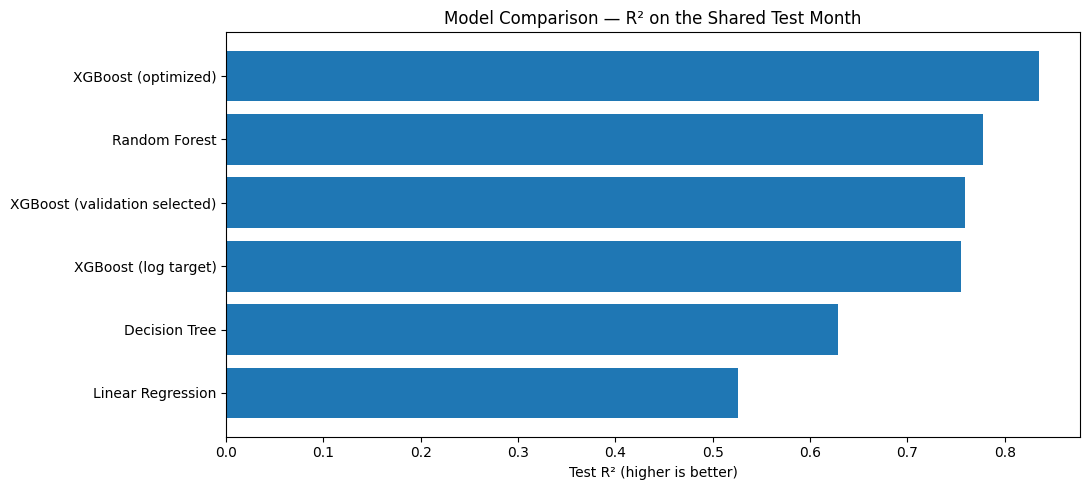

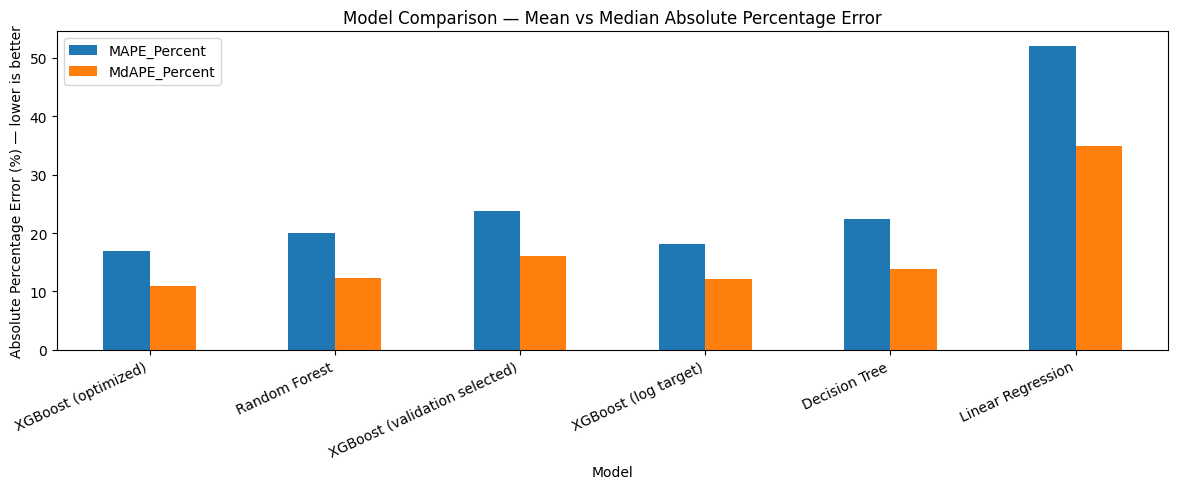

In [10]:
# R² for each model
plot_df = metrics_summary.sort_values("R2", ascending=True)
fig, ax = plt.subplots(figsize=(11, 5))
ax.barh(plot_df["Model"], plot_df["R2"])
ax.set_xlabel("Test R² (higher is better)")
ax.set_title("Model Comparison — R² on the Shared Test Month")
plt.tight_layout()
plt.show()

# MAPE vs MdAPE on the same test month
plot_pct = metrics_summary.set_index("Model")[["MAPE_Percent", "MdAPE_Percent"]]
plot_pct.plot(kind="bar", figsize=(12, 5))
plt.ylabel("Absolute Percentage Error (%) — lower is better")
plt.title("Model Comparison — Mean vs Median Absolute Percentage Error")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()

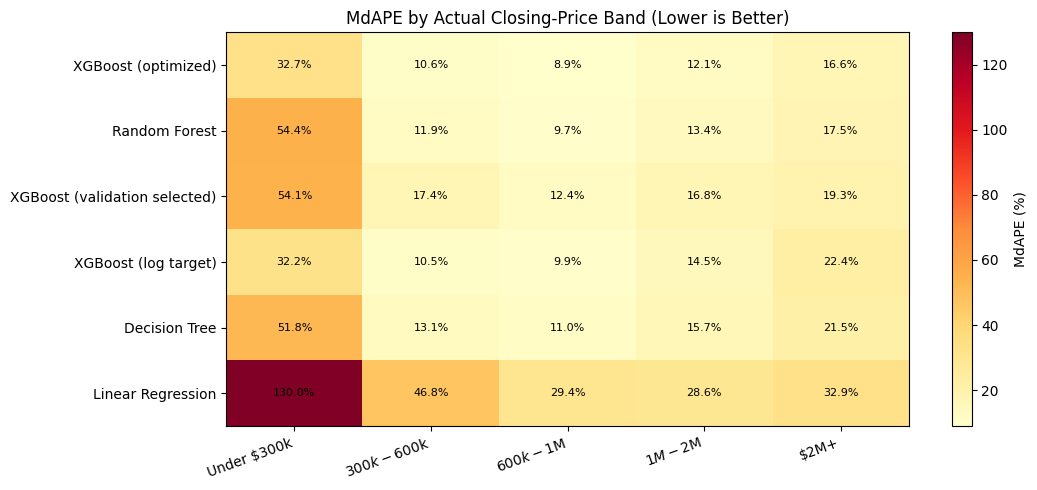

In [11]:
# Price-band MdAPE heatmap (all models, identical bands)
heatmap = price_band_metrics.pivot(
    index="Model", columns="Price_Band", values="MdAPE_Percent"
).reindex(index=metrics_summary["Model"], columns=PRICE_LABELS)

fig, ax = plt.subplots(figsize=(11, 5))
img = ax.imshow(heatmap.to_numpy(dtype=float), aspect="auto", cmap="YlOrRd")
ax.set_xticks(range(len(heatmap.columns)), labels=heatmap.columns)
ax.set_yticks(range(len(heatmap.index)), labels=heatmap.index)
plt.setp(ax.get_xticklabels(), rotation=20, ha="right")
for i in range(heatmap.shape[0]):
    for j in range(heatmap.shape[1]):
        value = heatmap.iloc[i, j]
        if pd.notna(value):
            ax.text(j, i, f"{value:.1f}%", ha="center", va="center", fontsize=8)
ax.set_title("MdAPE by Actual Closing-Price Band (Lower is Better)")
fig.colorbar(img, ax=ax, label="MdAPE (%)")
plt.tight_layout()
plt.show()

## 10. Automatic interpretation and limitations

This cell identifies the model with the best overall R², the model with the best overall MdAPE, and the strongest and weakest price bands **for the R²-leading model** when a band has at least the minimum sample size. It also reports how many observations fall in each price group.

**Interpretation cautions:**
1. MAPE can be dominated by unusually large percentage errors; compare it with MdAPE and MAE.
2. A model with the highest R² may not have the best MdAPE or MAE.
3. Earlier model configurations were partly selected using test results; a future untouched test month would provide a stronger final assessment.
4. Comparisons with **previous saved scores** may differ because the new analysis uses one dataset, shared feature columns, common imputation, and a consistent test set.
5. Engineered school-district columns are used only if they already exist in the loaded completed CSV. This notebook does **not** rerun the spatial join.

In [12]:
best_r2 = metrics_summary.loc[metrics_summary["R2"].idxmax()]
best_mdape = metrics_summary.loc[metrics_summary["MdAPE_Percent"].idxmin()]

print(f"BEST BY R²:    {best_r2['Model']} (R²={best_r2['R2']:.4f})")
print(f"BEST BY MdAPE: {best_mdape['Model']} (MdAPE={best_mdape['MdAPE_Percent']:.2f}%)")
print(f"\nEvaluated test month: {test_start:%Y-%m}")
print(f"Actual test sales: {len(TEST_DF):,}")

leader_bands = price_band_metrics.loc[
    (price_band_metrics["Model"] == best_r2["Model"])
    & (price_band_metrics["Enough_Rows_For_Insight"])
]
if not leader_bands.empty:
    best_band = leader_bands.loc[leader_bands["MdAPE_Percent"].idxmin()]
    worst_band = leader_bands.loc[leader_bands["MdAPE_Percent"].idxmax()]
    print(f"\nFor the R²-leading model, lowest MdAPE band: {best_band['Price_Band']} "
          f"({best_band['MdAPE_Percent']:.2f}%, n={best_band['Count']:,})")
    print(f"For the R²-leading model, highest MdAPE band: {worst_band['Price_Band']} "
          f"({worst_band['MdAPE_Percent']:.2f}%, n={worst_band['Count']:,})")
else:
    print("No price band has enough rows to claim a reliable comparison.")

print("\nShared test-set property counts by actual price band:")
print(pd.cut(TEST_DF["ClosePrice"], PRICE_BINS,
             labels=PRICE_LABELS, right=False).value_counts().reindex(PRICE_LABELS).to_string())

BEST BY R²:    XGBoost (optimized) (R²=0.8356)
BEST BY MdAPE: XGBoost (optimized) (MdAPE=10.94%)

Evaluated test month: 2024-01
Actual test sales: 7,069

For the R²-leading model, lowest MdAPE band: $600k-$1M (8.93%, n=2,514)
For the R²-leading model, highest MdAPE band: Under $300k (32.70%, n=245)

Shared test-set property counts by actual price band:
ClosePrice
Under $300k     245
$300k-$600k    1975
$600k-$1M      2514
$1M-$2M        1654
$2M+            681


## 11. Download the required CSV

The training/evaluation cell already **writes** `metrics_summary.csv` in the same working directory as this notebook. In Google Colab, find it in the left **Files** sidebar, or run the optional cell below to download it immediately.

**For your final Week 8 submission:** Include this executed notebook and `metrics_summary.csv`. You can optionally submit `price_band_metrics.csv` as supporting evidence for the price-band discussion. **Do not submit an unfilled template as model results.**

In [13]:
# Optional Colab download: remove the # at the start of each line to run it.
# from google.colab import files
# files.download("metrics_summary.csv")
# files.download("price_band_metrics.csv")

print("Output files generated:")
for name in ["metrics_summary.csv", "price_band_metrics.csv"]:
    p = Path(name)
    print(f"- {p.resolve()} ({p.stat().st_size:,} bytes)" if p.exists() else f"- Missing: {name}")

Output files generated:
- /content/metrics_summary.csv (1,244 bytes)
- /content/price_band_metrics.csv (3,024 bytes)
